In [290]:
import torch
from torch import nn
import torchvision
from torchvision import transforms
from torchvision import datasets
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

In [291]:
print(torch.__version__)
print(torchvision.__version__)

2.14.0+cu130
0.29.1+cu130


In [292]:
train_data=datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor(),
    target_transform=None
)

test_data=datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor(),
    target_transform=None
)

In [293]:
len(train_data),len(test_data)

(60000, 10000)

In [294]:
image,label=train_data[0]
[image,label]

[tensor([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000],
          [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
           0.0000, 0.0000, 0.0000, 0.0000, 0.0039, 0.0000, 0.0000, 0.0510,
           0.2863, 0.0000, 0.0000, 0.0039, 

In [295]:
class_names=train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [296]:
class_to_idx=train_data.class_to_idx
class_to_idx

{'T-shirt/top': 0,
 'Trouser': 1,
 'Pullover': 2,
 'Dress': 3,
 'Coat': 4,
 'Sandal': 5,
 'Shirt': 6,
 'Sneaker': 7,
 'Bag': 8,
 'Ankle boot': 9}

In [297]:
train_data.targets

tensor([9, 0, 0,  ..., 3, 0, 5])

In [298]:
image.shape,label

(torch.Size([1, 28, 28]), 9)

In [299]:
print(f"Image shape: {image.shape} -> [color_channels,height,width]")
print(f"Image label: {class_names[label]}")

Image shape: torch.Size([1, 28, 28]) -> [color_channels,height,width]
Image label: Ankle boot


In [300]:
image,label=train_data[0]
print(f"Image shape: {image.shape}")
print(f"Image shape: {image.squeeze().shape}")

Image shape: torch.Size([1, 28, 28])
Image shape: torch.Size([28, 28])


Text(0.5, 1.0, '9')

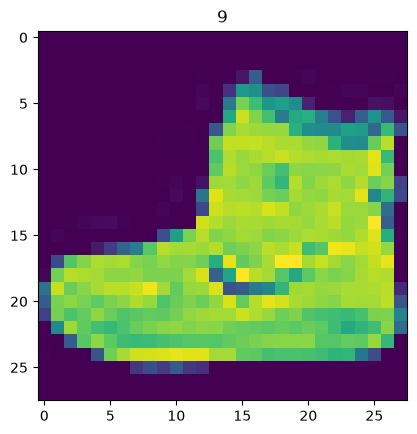

In [301]:

plt.imshow(image.squeeze())
plt.title(label)

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

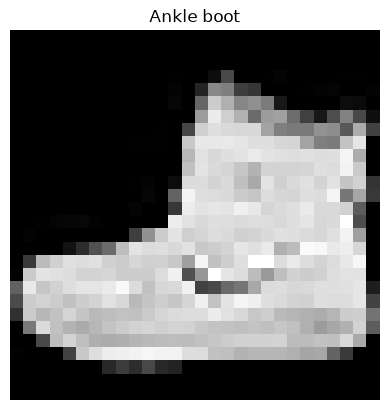

In [302]:
plt.imshow(image.squeeze(),cmap="gray")
plt.title(class_names[label])
plt.axis(False)

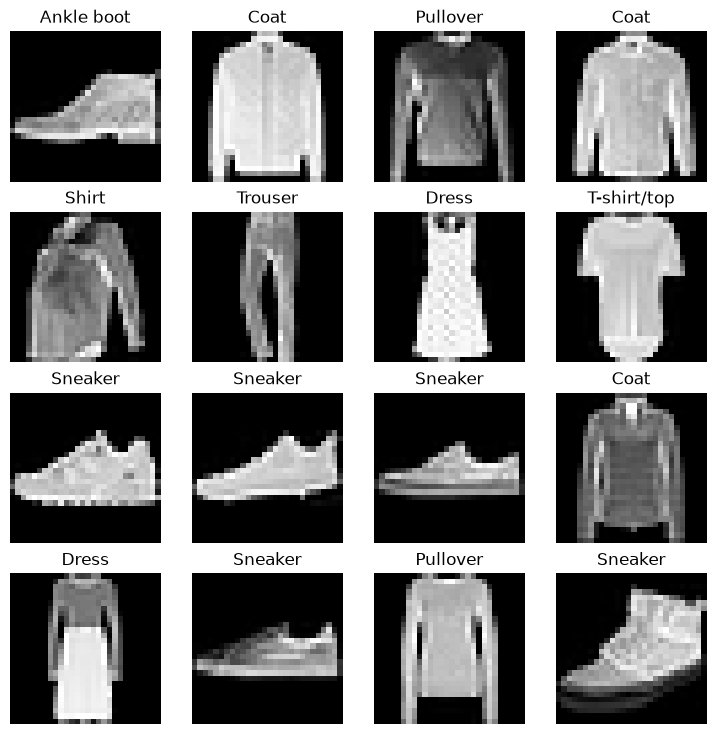

In [303]:

fig=plt.figure(figsize=(9,9))
rows,cols=4,4
for i in range(1,rows*cols+1):
    random_idx=torch.randint(0,len(train_data),size=[1]).item()
    img,label=train_data[random_idx]
    fig.add_subplot(rows,cols,i)
    plt.imshow(img.squeeze(),cmap="gray")
    plt.title(class_names[label])
    plt.axis(False)

In [304]:
train_data

Dataset FashionMNIST
    Number of datapoints: 60000
    Root location: data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [305]:
test_data

Dataset FashionMNIST
    Number of datapoints: 10000
    Root location: data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [306]:
from torch.utils.data import DataLoader

BATCH_SIZE=32
train_dataloader=DataLoader(dataset=train_data,
                            batch_size=BATCH_SIZE,
                            shuffle=True)
test_dataloader=DataLoader(dataset=test_data,
                           batch_size=BATCH_SIZE,
                           shuffle=False)

train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x770e5c14c350>,
 <torch.utils.data.dataloader.DataLoader at 0x770e5c14c890>)

In [307]:
print(f"Dataloaders: {train_dataloader,test_dataloader}")
print(f"Dataloaders: {len(train_dataloader),len(test_dataloader)}")

Dataloaders: (<torch.utils.data.dataloader.DataLoader object at 0x770e5c14c350>, <torch.utils.data.dataloader.DataLoader object at 0x770e5c14c890>)
Dataloaders: (1875, 313)


In [308]:
train_features_batch,train_labels_batch=next(iter(train_dataloader))
train_features_batch.shape,train_labels_batch.shape

(torch.Size([32, 1, 28, 28]), torch.Size([32]))

Image size: torch.Size([1, 28, 28])
Label: 1,label size: torch.Size([])


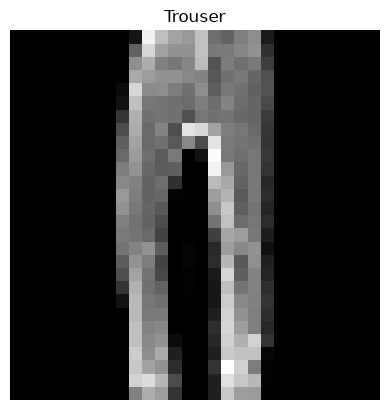

In [309]:
torch.manual_seed(42)
random_idx=torch.randint(0,len(train_features_batch),size=[1]).item()
img,label=train_features_batch[random_idx],train_labels_batch[random_idx]
plt.imshow(img.squeeze(),cmap="gray")
plt.title(class_names[label])
plt.axis(False)
print(f"Image size: {img.shape}")
print(f"Label: {label},label size: {label.shape}")

In [310]:
flatten_model=nn.Flatten()


x=train_features_batch[0]

In [311]:
#x.shape

output=flatten_model(x)
output.shape

torch.Size([1, 784])

In [312]:
class FashionMNISTModelV0(nn.Module):
    def __init__(self,input_shape,hidden_units,output_shape):
        super().__init__()

        self.layer_stack=nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape,out_features=hidden_units),
            nn.Linear(in_features=hidden_units,out_features=output_shape),
        )

    def forward(self,X):
        return self.layer_stack(X)

In [313]:
torch.manual_seed(42)

model_0=FashionMNISTModelV0(
    input_shape=784,
    hidden_units=10,
    output_shape=len(class_names)
)

model_0.to("cpu")

FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)

In [314]:
dummy_x=torch.rand([1,1,28,28])
model_0(dummy_x)

tensor([[-0.0315,  0.3171,  0.0531, -0.2525,  0.5959,  0.2112,  0.3233,  0.2694,
         -0.1004,  0.0157]], grad_fn=<AddmmBackward0>)

In [315]:
model_0.state_dict()

OrderedDict([('layer_stack.1.weight',
              tensor([[ 0.0273,  0.0296, -0.0084,  ..., -0.0142,  0.0093,  0.0135],
                      [-0.0188, -0.0354,  0.0187,  ..., -0.0106, -0.0001,  0.0115],
                      [-0.0008,  0.0017,  0.0045,  ..., -0.0127, -0.0188,  0.0059],
                      ...,
                      [-0.0116,  0.0273, -0.0344,  ...,  0.0176,  0.0283, -0.0011],
                      [-0.0230,  0.0257,  0.0291,  ..., -0.0187, -0.0087,  0.0001],
                      [ 0.0176, -0.0147,  0.0053,  ..., -0.0336, -0.0221,  0.0205]])),
             ('layer_stack.1.bias',
              tensor([-0.0093,  0.0283, -0.0033,  0.0255,  0.0017,  0.0037, -0.0302, -0.0123,
                       0.0018,  0.0163])),
             ('layer_stack.2.weight',
              tensor([[ 0.0614, -0.0687,  0.0021,  0.2718,  0.2109,  0.1079, -0.2279, -0.1063,
                        0.2019,  0.2847],
                      [-0.1495,  0.1344, -0.0740,  0.2006, -0.0475, -0.2514, -0.

In [316]:
import requests
from pathlib import Path

if Path("helper_functions.py").is_file():
    print("helper_functions.py already exsists, skipping download....")
else:
    print("Downloading helper_functions.py")
    request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    with open("helper_functions.py","wb") as f:
        f.write(request.content)

helper_functions.py already exsists, skipping download....


In [317]:
from helper_functions import accuracy_fn

loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_0.parameters(),lr=0.1)

In [318]:
from timeit import default_timer as timer

def print_train_time(start:float,end:float,device:torch.device=None):
    total_time=end-start

    print(f"Train time on {device}: {total_time:.3f} seconds")
    return total_time

In [319]:
start_time=timer()

end_time=timer()
print_train_time(start=start_time,end=end_time,device="cpu")

Train time on cpu: 0.000 seconds


1.2857999536208808e-05

In [320]:
from tqdm.auto import tqdm

torch.manual_seed(42)
train_time_start_on_cpu=timer()


epocs=5

for epoc in tqdm(range(epocs)):

    print(f"Epoc: {epoc}\n------")

    train_loss=0

    for batch,(X,y) in enumerate(train_dataloader):
        model_0.train()

        y_pred=model_0(X)

        loss=loss_fn(y_pred,y)
        train_loss+=loss.item()

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        if batch %400==0:
            print(f"Looked at {batch*len(X)}/{len(train_dataloader.dataset)} samples ")

    train_loss /=len(train_dataloader)

    test_loss,test_acc=0,0

    model_0.eval()

    with torch.inference_mode():

        for X_test, y_test in test_dataloader:
            test_pred=model_0(X_test)

            test_loss+=loss_fn(test_pred,y_test)

            test_acc+=accuracy_fn(y_true=y_test,y_pred=test_pred.argmax(dim=1))

        test_loss/=len(test_dataloader)

        test_acc/=len(test_dataloader)

    print(f"\nTrain loss: {train_loss:.4f} | Test loss: {test_loss:.4f}, Test acc: {test_acc:.4f}")

train_time_end_on_cpu=timer()

total_train_time_model_0=print_train_time(
    start=train_time_start_on_cpu,
    end=train_time_end_on_cpu,
    device=str(next(model_0.parameters()).device)
)



  0%|          | 0/5 [00:00<?, ?it/s]

Epoc: 0
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


 20%|██        | 1/5 [00:03<00:12,  3.20s/it]


Train loss: 0.5904 | Test loss: 0.5095, Test acc: 82.0387
Epoc: 1
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


 40%|████      | 2/5 [00:06<00:09,  3.18s/it]

...


Train loss: 0.4550 | Test loss: 0.4766, Test acc: 83.4265
Epoc: 3
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


 80%|████████  | 4/5 [00:16<00:04,  4.35s/it]


Train loss: 0.4425 | Test loss: 0.4631, Test acc: 83.7460
Epoc: 4
------
Looked at 0/60000 samples 
Looked at 12800/60000 samples 
Looked at 25600/60000 samples 
Looked at 38400/60000 samples 
Looked at 51200/60000 samples 


100%|██████████| 5/5 [00:22<00:00,  4.57s/it]


Train loss: 0.4358 | Test loss: 0.4687, Test acc: 83.2668
Train time on cpu: 22.839 seconds


In [321]:
torch.manual_seed(42)

def eval_model(model:torch.nn.Module,data_loader: torch.utils.data.DataLoader,loss_fn: torch.nn.Module,accuracy_fn):
    loss, acc = 0, 0
    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:
            y_pred=model(X)

            loss+=loss_fn(y_pred,y)

            acc+=accuracy_fn(y,y_pred.argmax(dim=1))

        loss/=len(data_loader)
        acc/=len(data_loader)

    return {"model_name":model.__class__.__name__,"model_loss":loss.item(),"model_acc":acc}

model_0_results=eval_model(model=model_0,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4686938524246216,
 'model_acc': 83.2667731629393}

In [322]:
import torch

device="cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [323]:
class FashionMinist(nn.Module):
    def __init__(self,input_layer,hidden_layer,output_layer):
        super().__init__()
        self.stacks_layer=nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_layer,out_features=hidden_layer),
            nn.ReLU(),
            nn.Linear(in_features=hidden_layer,out_features=output_layer),
            nn.ReLU()
        )
    def forward(self,x:torch.Tensor):
        return self.stacks_layer(x)
    

In [324]:
next(model_0.parameters()).device

device(type='cpu')

In [325]:
device

'cuda'

In [326]:
torch.manual_seed(42)

model_1=FashionMinist(784,10,len(class_names)).to(device)

In [327]:
next(model_1.parameters()).device

device(type='cuda', index=0)

In [328]:
from helper_functions import accuracy_fn

loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.01)

In [329]:
torch.manual_seed(42)


In [330]:
def train_step(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               optimizer:torch.optim.Optimizer,
               accuracy_fn,
               device:torch.device=device):
    train_loss,train_acc=0,0

    model.train()

    for batch,(X,y) in enumerate(data_loader):

        X,y=X.to(device),y.to(device)

        y_pred=model(X)

        loss=loss_fn(y_pred,y)
        train_loss+=loss.item()
        train_acc+=accuracy_fn(y,y_pred.argmax(dim=1))

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    train_loss /=len(data_loader)
    train_acc /=len(data_loader)

    print(f"Train loss: {train_loss:.5f} | Train acc: {train_acc:.5f}%")

In [331]:
def test_step(model:torch.nn.Module,
               data_loader:torch.utils.data.DataLoader,
               loss_fn:torch.nn.Module,
               accuracy_fn,
               device:torch.device=device):

    test_loss,test_acc=0,0
    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:
            X,y=X.to(device),y.to(device)

            test_pred=model(X)

            test_loss+=loss_fn(test_pred,y)
            test_acc+=accuracy_fn(y,test_pred.argmax(dim=1))
        test_loss/=len(data_loader)
        test_acc/=len(data_loader)

        print(f"Test loss: {test_loss:.5f} | Test acc: {test_acc:.2f}%")

In [332]:
torch.manual_seed(42)
train_time_start_on_gpu=timer()


epocs=6
for epoc in tqdm(range(epocs)):
    print(f"Epoc: {epoc}\n-------------------")
    train_step(model=model_1,data_loader=train_dataloader,loss_fn=loss_fn,optimizer=optimizer,accuracy_fn=accuracy_fn,device=device)


    test_step(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn,device=device)

train_time_end_on_gpu=timer()

total_train_time_model_1=print_train_time(start=train_time_start_on_gpu,end=train_time_end_on_gpu,device=device)

  0%|          | 0/6 [00:00<?, ?it/s]

Epoc: 0
-------------------
Train loss: 1.42179 | Train acc: 54.28667%


 17%|█▋        | 1/6 [00:04<00:20,  4.17s/it]

Test loss: 1.12168 | Test acc: 62.15%
Epoc: 1
-------------------
Train loss: 1.03359 | Train acc: 64.61167%


 33%|███▎      | 2/6 [00:08<00:16,  4.21s/it]

...

Test loss: 0.93870 | Test acc: 65.94%
Epoc: 4
-------------------
Train loss: 0.91089 | Train acc: 67.04167%


 83%|████████▎ | 5/6 [00:20<00:04,  4.12s/it]

Test loss: 0.92726 | Test acc: 65.99%
Epoc: 5
-------------------
Train loss: 0.89804 | Train acc: 67.27667%


100%|██████████| 6/6 [00:24<00:00,  4.12s/it]

Test loss: 0.91716 | Test acc: 66.25%
Train time on cuda: 24.731 seconds


In [333]:
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.4686938524246216,
 'model_acc': 83.2667731629393}

In [334]:
total_train_time_model_0

22.83866575600041

In [335]:
torch.manual_seed(42)

def eval_model(model:torch.nn.Module,data_loader: torch.utils.data.DataLoader,loss_fn: torch.nn.Module,accuracy_fn):
    loss, acc = 0, 0
    model.eval()

    with torch.inference_mode():
        for X,y in data_loader:

            X,y=X.to(device),y.to(device)
            y_pred=model(X)

            loss+=loss_fn(y_pred,y)

            acc+=accuracy_fn(y,y_pred.argmax(dim=1))

        loss/=len(data_loader)
        acc/=len(data_loader)

    return {"model_name":model.__class__.__name__,"model_loss":loss.item(),"model_acc":acc}

In [336]:
model_1_results=eval_model(model=model_1,data_loader=test_dataloader,loss_fn=loss_fn,accuracy_fn=accuracy_fn)

In [337]:
model_1_results

{'model_name': 'FashionMinist',
 'model_loss': 0.9171638488769531,
 'model_acc': 66.25399361022365}

In [338]:
class FashionMNISTModel(nn.Module):
    def __init__(self,
            input_shape: int,
            hidden_shape: int,
            output_shape: int):
        super().__init__()

        self.conv_block_1=nn.Sequential(
            nn.Conv2d(in_channels=input_shape,out_channels=hidden_shape,kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_shape,out_channels=hidden_shape,kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.conv_block_2=nn.Sequential(
            nn.Conv2d(in_channels=hidden_shape,out_channels=hidden_shape,kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_shape,out_channels=hidden_shape,kernel_size=3,stride=1,padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier=nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_shape*7*7,out_features=output_shape)
        )

    def forward(self,x):
        x=self.conv_block_1(x)
        # print(x.shape)
        x=self.conv_block_2(x)
        # print(x.shape)
        x=self.classifier(x)
        return x

In [339]:
image.shape

torch.Size([1, 28, 28])

In [340]:
torch.manual_seed(42)
model_2=FashionMNISTModel(input_shape=1,hidden_shape=10,output_shape=len(class_names)).to(device)

In [341]:
model_2.state_dict()

OrderedDict([('conv_block_1.0.weight',
              tensor([[[[ 0.2548,  0.2767, -0.0781],
                        [ 0.3062, -0.0730,  0.0673],
                        [-0.1623,  0.1958,  0.2938]]],
              
              
                      [[[-0.2445,  0.2897,  0.0624],
                        [ 0.2463,  0.0451,  0.1607],
                        [-0.0471,  0.2570,  0.0493]]],
              
              
                      [[[-0.1556,  0.0850, -0.1536],
                        [-0.0391, -0.1354,  0.2211],
                        [-0.2631, -0.1537, -0.0941]]],
              
              
                      [[[-0.2004,  0.0315, -0.3292],
                        [ 0.3010, -0.2832,  0.2573],
                        [ 0.0555, -0.1082,  0.2060]]],
              
              
                      [[[ 0.0520,  0.2693,  0.0364],
                        [-0.1051,  0.0896, -0.0904],
                        [ 0.1403,  0.2976,  0.1927]]],
              
              
      

In [342]:
torch.manual_seed(42)


images=torch.randn(size=(32,3,64,64))
test_image=images[0]
print(f"Images batch shape: {images.shape}")
print(f"Test image: {test_image.shape}")
print(f"Test image:\n {test_image}")


Images batch shape: torch.Size([32, 3, 64, 64])
Test image: torch.Size([3, 64, 64])
Test image:
 tensor([[[ 1.9269,  1.4873,  0.9007,  ...,  1.8446, -1.1845,  1.3835],
         [ 1.4451,  0.8564,  2.2181,  ...,  0.3399,  0.7200,  0.4114],
         [ 1.9312,  1.0119, -1.4364,  ..., -0.5558,  0.7043,  0.7099],
         ...,
         [-0.5610, -0.4830,  0.4770,  ..., -0.2713, -0.9537, -0.6737],
         [ 0.3076, -0.1277,  0.0366,  ..., -2.0060,  0.2824, -0.8111],
         [-1.5486,  0.0485, -0.7712,  ..., -0.1403,  0.9416, -0.0118]],

        [[-0.5197,  1.8524,  1.8365,  ...,  0.8935, -1.5114, -0.8515],
         [ 2.0818,  1.0677, -1.4277,  ...,  1.6612, -2.6223, -0.4319],
         [-0.1010, -0.4388, -1.9775,  ...,  0.2106,  0.2536, -0.7318],
         ...,
         [ 0.2779,  0.7342, -0.3736,  ..., -0.4601,  0.1815,  0.1850],
         [ 0.7205, -0.2833,  0.0937,  ..., -0.1002, -2.3609,  2.2465],
         [-1.3242, -0.1973,  0.2920,  ...,  0.5409,  0.6940,  1.8563]],

        [[-0.7978, 

In [343]:
conv_layer=nn.Conv2d(in_channels=3,out_channels=10,kernel_size=(3,3),stride=1,padding=1)

conv_output=conv_layer(test_image)
conv_output

tensor([[[ 1.6446e-01, -6.2518e-01, -7.7713e-01,  ..., -3.2504e-01,
          -3.1604e-01,  4.5352e-01],
         [ 3.5455e-01, -2.8778e-01, -6.0596e-02,  ...,  6.6224e-01,
          -2.3216e-01,  7.7080e-01],
         [-4.5420e-02, -9.8911e-01, -4.0099e-01,  ..., -1.8552e-01,
          -5.7622e-01,  4.2301e-01],
         ...,
         [ 2.9288e-01, -1.4512e-01, -1.1566e-01,  ..., -3.6626e-01,
           3.5645e-01,  2.8384e-01],
         [ 2.0746e-01,  3.6096e-02,  1.5214e-01,  ..., -4.9680e-01,
          -7.2258e-01, -8.3858e-02],
         [-3.2457e-01, -3.2326e-01,  9.5475e-02,  ...,  5.9960e-01,
           3.2819e-01,  3.6604e-01]],

        [[ 1.2406e+00,  2.2794e-01, -1.8362e-01,  ..., -6.3520e-01,
          -7.5413e-01,  4.0612e-01],
         [ 4.1380e-01, -1.0853e+00, -1.6079e+00,  ..., -1.7643e+00,
           2.5263e-01,  3.8844e-01],
         [ 5.3442e-01, -8.2507e-01,  6.3866e-01,  ...,  4.8068e-01,
           8.4869e-01, -1.5706e-01],
         ...,
         [-5.6923e-03, -5

In [344]:
test_image.unsqueeze(0).shape

torch.Size([1, 3, 64, 64])

In [345]:
torch.manual_seed(42)
conv_output=conv_layer(test_image.unsqueeze(0))
conv_output.shape

torch.Size([1, 10, 64, 64])

In [346]:
test_image.shape

torch.Size([3, 64, 64])

In [347]:
test_image.unsqueeze(0).shape

torch.Size([1, 3, 64, 64])

In [348]:
print(f"Test image original shape: {test_image.shape}")
print(f"Test image with unsqueezed: {test_image.squeeze().shape}")

max_pool_layer=nn.MaxPool2d(kernel_size=3)

test_image_through_conv=conv_layer(test_image.unsqueeze(dim=0))
print(f"Shape after going through conv_layer(): {test_image_through_conv.shape}")

test_image_through_conv_and_max_pool=max_pool_layer(test_image_through_conv)
print(f"SHape conv: {test_image_through_conv_and_max_pool.shape}")

Test image original shape: torch.Size([3, 64, 64])
Test image with unsqueezed: torch.Size([3, 64, 64])
Shape after going through conv_layer(): torch.Size([1, 10, 64, 64])
SHape conv: torch.Size([1, 10, 21, 21])


In [349]:
random_samples=torch.randn(size=(1,1,2,2))
print(random_samples.shape)
max_pool_layer=nn.MaxPool2d(kernel_size=2)

max_pool_tensor=max_pool_layer(random_samples)
print(f"\nMac pool tensor:\n {max_pool_tensor}")
max_pool_tensor.shape

torch.Size([1, 1, 2, 2])

Mac pool tensor:
 tensor([[[[0.3367]]]])


torch.Size([1, 1, 1, 1])

In [350]:
random_samples=torch.randn(size=(1,3,4,4))
print(random_samples.shape)
max_pool_layer=nn.MaxPool2d(kernel_size=2)

max_pool_tensor=max_pool_layer(random_samples)
print(f"\nMac pool tensor:\n {max_pool_tensor}")
max_pool_tensor.shape

torch.Size([1, 3, 4, 4])

Mac pool tensor:
 tensor([[[[ 1.7878,  0.5201],
          [ 2.0024,  2.3228]],

         [[ 0.3559,  0.2415],
          [-0.0631,  0.8034]],

         [[ 1.3123,  1.5736],
          [ 1.1790,  2.2667]]]])


torch.Size([1, 3, 2, 2])

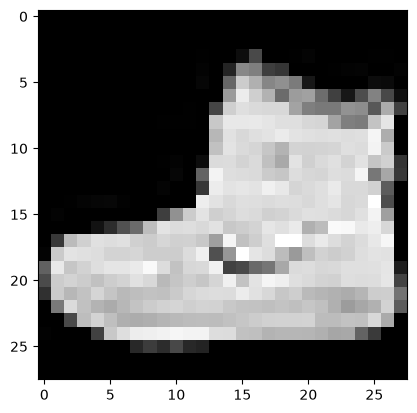

In [351]:
plt.imshow(image.squeeze(),cmap="gray")

In [352]:
rand_image_tensor=torch.randn(size=(1,28,28))

rand_image_tensor.shape

torch.Size([1, 28, 28])

In [353]:
model_2(rand_image_tensor.unsqueeze(0).to(device))

tensor([[ 0.0467, -0.0998,  0.0991, -0.0388,  0.0102,  0.0346,  0.0050,  0.0128,
         -0.0139, -0.0179]], device='cuda:0', grad_fn=<AddmmBackward0>)

In [354]:
model_2(rand_image_tensor.unsqueeze(0).to(device)).shape

torch.Size([1, 10])

In [355]:
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.SGD(params=model_2.parameters(),lr=0.01)

In [356]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

from timeit import default_timer as Timer
train_time_start_model_2=timer()


epocs=3

for epoc in tqdm(range(epocs)):
    print(f"Epoc: {epoc}\n------------")

    train_step(model=model_2,
               data_loader=train_dataloader,
               loss_fn=loss_fn,
               optimizer=optimizer,
               accuracy_fn=accuracy_fn,
               device=device)

    test_step(
        model=model_2,
        data_loader=test_dataloader,
        loss_fn=loss_fn,
        accuracy_fn=accuracy_fn,
        device=device
    )

train_time_end_model_2=timer()

total_train_time_model_2=print_train_time(train_time_start_model_2,train_time_end_model_2,device=device)

  0%|          | 0/3 [00:00<?, ?it/s]

Epoc: 0
------------
Train loss: 1.03783 | Train acc: 62.33667%


 33%|███▎      | 1/3 [00:05<00:10,  5.46s/it]

Test loss: 0.62511 | Test acc: 76.84%
Epoc: 1
------------
Train loss: 0.54939 | Train acc: 80.01000%


 67%|██████▋   | 2/3 [00:10<00:05,  5.46s/it]

Test loss: 0.49835 | Test acc: 81.55%
Epoc: 2
------------
Train loss: 0.45559 | Train acc: 83.53833%


100%|██████████| 3/3 [00:16<00:00,  5.37s/it]

Test loss: 0.44110 | Test acc: 84.15%
Train time on cuda: 16.114 seconds


In [357]:
model_2_results=eval_model(
    model=model_2,
    data_loader=test_dataloader,
    loss_fn=loss_fn,
    accuracy_fn=accuracy_fn)
model_2_results

{'model_name': 'FashionMNISTModel',
 'model_loss': 0.44109535217285156,
 'model_acc': 84.14536741214057}

In [358]:
import pandas as pd

compare_results=pd.DataFrame([
    model_0_results,model_1_results,model_2_results
])

compare_results

,model_name,model_loss,model_acc
0,FashionMNISTModelV0,0.468694,83.266773
1,FashionMinist,0.917164,66.253994
2,FashionMNISTModel,0.441095,84.145367


In [359]:
compare_results["training_time"]=[total_train_time_model_0,total_train_time_model_1,total_train_time_model_1]

In [360]:
compare_results

,model_name,model_loss,model_acc,training_time
0,FashionMNISTModelV0,0.468694,83.266773,22.838666
1,FashionMinist,0.917164,66.253994,24.731071
2,FashionMNISTModel,0.441095,84.145367,24.731071


<Axes: ylabel='model_name'>

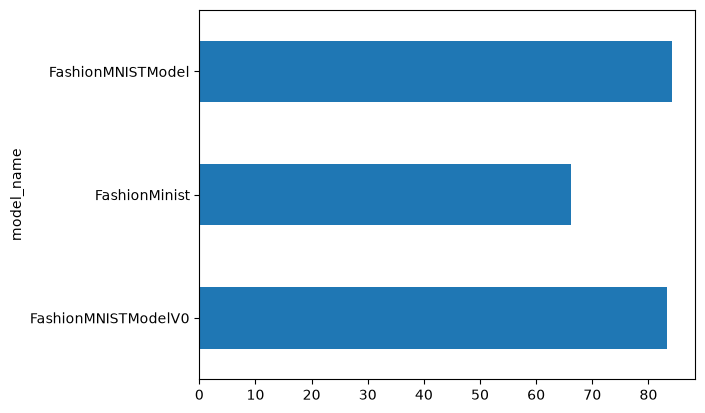

In [361]:
compare_results.set_index("model_name")["model_acc"].plot(kind="barh")

In [362]:
def make_predictions(model: torch.nn.Module,
                     data: list,
                     device: torch.device=device):

    pred_probs=[]
    model.eval()

    with torch.inference_mode():
        for sample in data:
            sample=torch.unsqueeze(sample,dim=0).to(device)

            pred_logit=model(sample)

            pred_prob=torch.softmax(pred_logit.squeeze(),dim=0)

            pred_probs.append(pred_prob.cpu())

    return torch.stack(pred_probs)


In [370]:
import random
# random.seed(42)

test_samples=[]
test_labels=[]

for sample,label in random.sample(list(test_data),k=9):
    test_samples.append(sample)
    test_labels.append(label)

test_samples[0].shape


torch.Size([1, 28, 28])

Text(0.5, 1.0, 'Sandal')

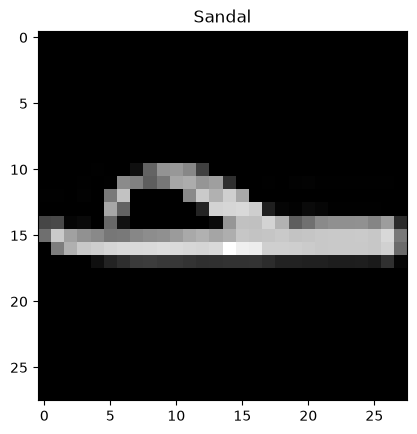

In [371]:
plt.imshow(test_samples[0].squeeze(),cmap="gray")
plt.title(class_names[test_labels[0]])

In [372]:
pred_probs=make_predictions(model=model_2,data=test_samples)

pred_probs[:2]

tensor([[1.9199e-05, 4.4742e-05, 6.1425e-05, 4.0024e-04, 4.9288e-06, 9.6121e-01,
         3.1691e-05, 2.9390e-02, 8.8229e-03, 1.9854e-05],
        [9.6779e-02, 4.1855e-03, 4.7680e-01, 3.1865e-02, 1.5103e-02, 3.0675e-03,
         2.4129e-01, 1.5330e-04, 1.2999e-01, 7.6280e-04]])

In [373]:
test_labels

[5, 2, 0, 1, 2, 2, 1, 4, 4]

In [374]:
pred_classes=pred_probs.argmax(dim=1)
pred_classes

tensor([5, 2, 0, 1, 2, 2, 1, 4, 4])

In [375]:
test_labels

[5, 2, 0, 1, 2, 2, 1, 4, 4]

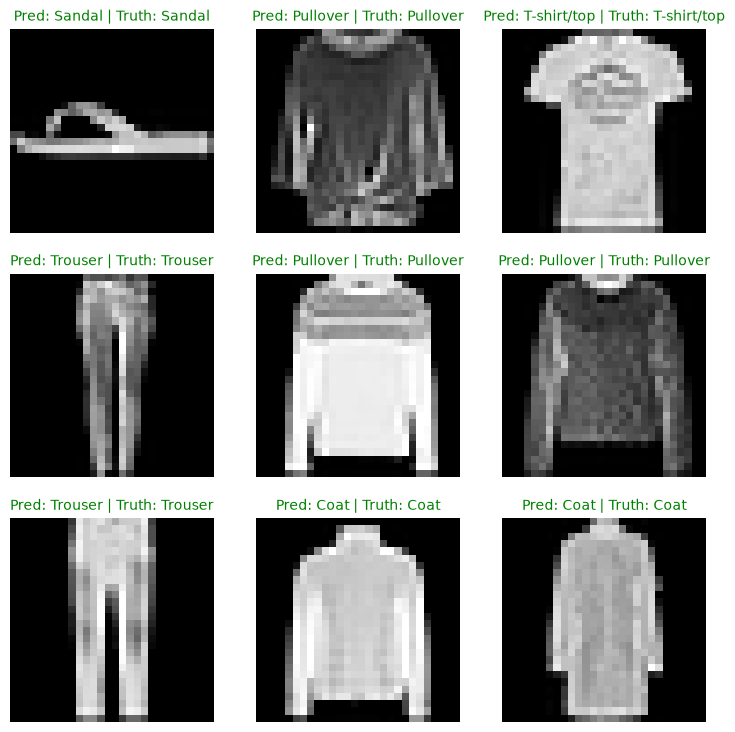

In [376]:
plt.figure(figsize=(9,9))
nrows=3
ncols=3

for i, sample in enumerate(test_samples):
    plt.subplot(nrows,ncols,i+1)

    plt.imshow(sample.squeeze(),cmap="gray")

    pred_label=class_names[pred_classes[i]]

    truth_label=class_names[test_labels[i]]

    title_text=f"Pred: {pred_label} | Truth: {truth_label}"

    if pred_label == truth_label:
        plt.title(title_text,fontsize=10,c="g")
    else:
        plt.title(title_text,fontsize=10,c="r")
    plt.axis(False);

In [381]:
from tqdm.auto import tqdm

y_preds=[]

model_2.eval()

with torch.inference_mode():
    for X,y in tqdm(test_dataloader,desc="Making predictions..."):
        X,y=X.to(device),y.to(device)

        y_logit=model_2(X)

        y_pred=torch.softmax(y_logit.squeeze(),dim=0).argmax(dim=1)

        y_preds.append(y_pred.cpu())

print(y_preds)
y_pred_tensor=torch.cat(y_preds)
y_pred_tensor[:10]

Making predictions...: 100%|██████████| 313/313 [00:00<00:00, 809.94it/s]


[tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7, 4, 5, 8, 3, 4, 3, 2, 6, 8, 0, 2, 7, 7, 5,
        3, 2, 6, 3, 9, 3, 8, 8]), tensor([3, 3, 8, 0, 7, 5, 7, 9, 0, 1, 3, 7, 4, 7, 2, 3, 4, 6, 2, 4, 5, 8, 2, 2,
        8, 4, 8, 0, 7, 7, 8, 5]), tensor([1, 3, 3, 3, 7, 8, 7, 0, 2, 6, 4, 3, 3, 2, 8, 4, 3, 8, 5, 9, 5, 0, 3, 2,
        0, 2, 5, 3, 6, 7, 1, 8]), tensor([6, 1, 4, 2, 3, 6, 7, 2, 7, 8, 5, 7, 9, 4, 2, 5, 7, 6, 5, 2, 8, 6, 7, 8,
        6, 0, 9, 9, 3, 6, 8, 4]), tensor([1, 5, 4, 3, 5, 1, 8, 4, 2, 1, 2, 5, 1, 6, 0, 0, 1, 6, 1, 3, 2, 2, 6, 6,
        3, 6, 5, 2, 4, 7, 9, 3]), tensor([7, 2, 3, 5, 0, 9, 2, 7, 4, 2, 0, 5, 4, 1, 2, 1, 3, 6, 9, 1, 0, 7, 3, 8,
        7, 9, 5, 4, 4, 7, 3, 2]), tensor([3, 6, 3, 2, 8, 3, 6, 1, 3, 0, 2, 9, 2, 4, 6, 7, 9, 8, 4, 3, 8, 4, 1, 3,
        3, 6, 7, 2, 8, 5, 3, 0]), tensor([7, 7, 3, 6, 7, 0, 7, 8, 9, 2, 9, 0, 5, 1, 4, 2, 5, 3, 9, 6, 2, 8, 6, 4,
        3, 4, 9, 7, 3, 3, 8, 4]), tensor([8, 5, 2, 3, 0, 4, 8, 6, 6, 2, 3, 8, 9, 6, 1, 3, 6, 4, 3, 0, 8, 3, 7, 4,
       

tensor([9, 2, 1, 1, 6, 1, 4, 6, 5, 7])

In [382]:
len(y_pred_tensor)

10000

In [383]:
import torchmetrics